# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [27]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

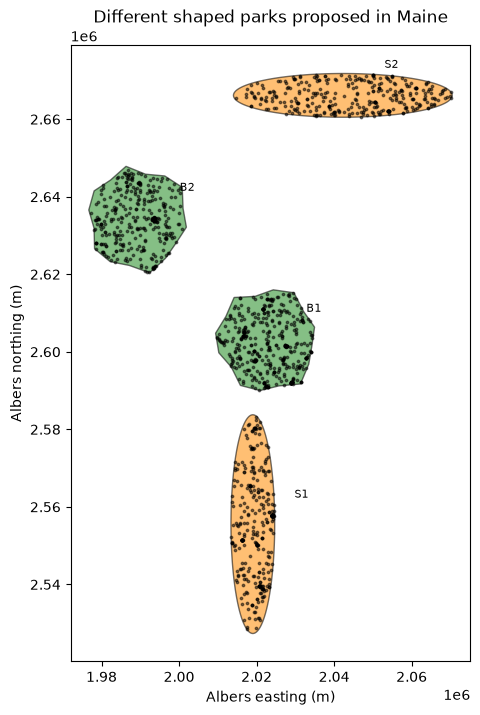

In [35]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().
records.groupby("scenario").size()
# Plot the parks and occurrence points; label B1, B2, S1, and S2.
parks = parks.assign(measured_km2=parks.area / 1e6) # convert area in sq meters to sq km

display(parks.groupby("scenario").measured_km2.sum())

fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

# Annotate parks by name
for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(f"{row.Index}", (anchor.x, anchor.y),
                xytext=(30, 20), textcoords="offset points", fontsize=8)

ax.set(title="Different shaped parks proposed in Maine",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:* The parks have the same area, but in addition to shape they also have different distances to the edge. For example, the center of the blob parks is farther from an edge than the center of the stripe plots, which could affect biological diversity.

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [40]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* There are 67 species in the community. Ambystoma maculatum appears to be much more abundant in the blob parks than in the stripe parks, and its distribution within each category is relatively even across the two parks.

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [41]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

In [43]:
park_metrics

,n_records,richness,shannon
park_id,,,
B1,436.0,51.0,3.323911
B2,409.0,54.0,3.516299
S1,328.0,49.0,3.320299
S2,327.0,57.0,3.711955


In [45]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)
# Add park names and scenarios from parks.
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
# Add evenness = np.exp(shannon) / richness, as in Lab10.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
# Display the table and make a simple richness or Shannon plot.
display(park_metrics)

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* The richest park is Silver Brook Reach, which has the highest Shannon diversity and the highest evenness. However, adding 100 records of one species that is already common would not increase the richness, but it would decrease the diversity and evenness.

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [55]:
designs = ["blob", "stripe"]
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)

# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})

# For each design, find its two rows in park_metrics.
for design in designs:
    local_parks = park_metrics[park_metrics.scenario == design]
    alpha = local_parks.richness.mean()
    gamma = design_metrics.loc[design, "gamma_richness"]
    design_metrics.loc[design, "mean_park_alpha"] = alpha
    design_metrics.loc[design, "beta_ratio"] = gamma / alpha
    design_metrics.loc[design, "sum_park_richness"] = local_parks.richness.sum()
    design_metrics.loc[design, "area_km2"] = parks[parks.scenario == design].measured_km2.sum()
display(design_metrics)
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
blob,845.0,60.0,3.460793,52.5,1.142857,105.0,1000.000589
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:* the stripe design has a higher gamma diversity, which is explained by both higher mean park alpha diversity and higher beta diversity, meaning each stripe park has high diversity within intself and compared to the other strip park.

In [61]:
# Make blob_species and stripe_species from design_counts.
blob_counts = design_counts.loc["blob"]
stripe_counts = design_counts.loc["stripe"]
blob_species = set(blob_counts[blob_counts > 0].index)
stripe_species = set(stripe_counts[stripe_counts > 0].index)
# Print species unique to each design.
print("Only in the blob parks:", sorted(blob_species - stripe_species))
print("Only in the stripe parks:", sorted(stripe_species - blob_species))
print("In both strategies:", len(stripe_species & blob_species))

Only in the blob parks: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in the stripe parks: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
In both strategies: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [63]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)

# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )

# Display the table.
display(jaccard_distances.round(2))

B1 versus B2: 0.25


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* B1 and B2 have a Jaccard distance of 0.25, which is lower than the Jaccard distance between S1 and S2 of 0.32. This indicates that stripe parks have less similarity between the two of them, which is in agreement with the higher beta ratio for stripe parks. Jaccard alone cannot distinguish species replacement from differences in richness because there could be completely different species between parks or different levels of evenness, which would explain high Jaccard distances.

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [70]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))
# For each within-design pair, divide each row by its sum and compare again.
a_counts = community.loc["B1"]
b_counts = community.loc["B2"]
a_frequencies = a_counts / a_counts.sum()
b_frequencies = b_counts / b_counts.sum()
print("B1 versus B2, relative frequencies:", braycurtis(a_frequencies, b_frequencies))

c_counts = community.loc["S1"]
d_counts = community.loc["S2"]
c_frequencies = c_counts / c_counts.sum()
d_frequencies = d_counts / d_counts.sum()
print("S1 versus S2, relative frequencies:", braycurtis(c_frequencies, d_frequencies))

B1 versus B2: 0.19763313609467456


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


B1 versus B2, relative frequencies: 0.19325497409210204
S1 versus S2, relative frequencies: 0.3037032893264713


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* Yes, Bray-Curtis tells the same story and Jaccard. Bray-Curtis distance for B1-B2 is 0.24, which is lower that the distance for S1-S2 of 0.30. Unequal record totals could affect values because for smaller communities, each species added or subtracted carries more weight because it is a larger proportion of the total richness. When looking at relative frequencies, the same story is told but the magnitude of difference is greater.

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [75]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []
    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
        richness_samples.append(sample.species.nunique())
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)
# Use np.mean and np.quantile, then display the table.
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,57.423333,54.0,60.0
stripe,655.0,63.000000,63.0,63.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* Nope--this still leads to the stripe scenario having higher richness, with non-overlapping confidence intervals. it's interesting because the confidence interval for the stripe parks is 0, meaning that 63 species are consistently sampled every time. That suggests that not only is richness higher, it is also more stable than the blob parks. Biases that remain include uneven sampling effort or detection (sampling bias) and uneven spatial representation (could be sampling or simulation bias).

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [79]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

print("Record-rare species:", rare_species)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Record-rare species: ['Ambystoma laterale', 'Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton evergreenii', 'Fictotriton moonensis', 'Fictotriton thorni', 'Fictotriton vernalensis', 'Imaginarana emberi', 'Imaginarana fernensis', 'Imaginarana granitica', 'Imaginarana humicola', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Lithobates pipiens', 'Rana arvalis', 'Sylvophantoma argentea', 'Sylvophantoma cedrina', 'Sylvophantoma echinata', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii', 'Sylvophantoma inverna', 'Sylvophantoma noctiluca', 'Sylvophantoma sprucea', 'Sylvophantoma willowii']


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [86]:
# Copy the restriction_metrics function from Lab10.
def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results
# Calculate park_restriction = restriction_metrics(community).
park_restriction = restriction_metrics(community)
# Display park_metrics.join(park_restriction).
park_metrics.join(park_restriction)

# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.
for design, park_ids in {
    "blob": ["B1", "B2"],
    "stripe": ["S1", "S2"]
}.items():
    design_counts = community.loc[park_ids]
    rare_count = design_counts[rare_species].gt(0).any(axis=0).sum()
    print(design, rare_count)

blob 17
stripe 20


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* Yes--parks with high WE also have high CWE. Neither design seems to capture more record-rare species in general, but rather there is variation between parks within each design. I don't see any rare species that have more than 1 or two records, though. These results do not prove that a species is endemic to a particular park or has a small population because the metrics measure recorded species occurrences, not actual geographic distributions or population sizes.

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [88]:
output_dir = Path("outputs/Assignment11")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").
park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "park_design_metrics.csv")
jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")
rarefaction.to_csv(output_dir / "park_rarefaction.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:* 
I would recommend the stripe park design for conserving amphibian diversity based on the results of this simulation. Although both designs protect approximately 1,000 km² and contain two parks of 500 km² each, the stripe design captures greater overall species richness and shows greater species complementarity between its parks.

The stripe design has a gamma diversity of 63 species, compared with 60 species for the blob design. Mean alpha diversity is also slightly higher for stripes (53 species) than blobs (52.5 species). The beta ratio is higher for stripes (1.19 versus 1.14), suggesting that the two stripe parks contain somewhat more distinct species assemblages. This is supported by the species lists: the blob parks contain four species not recorded in the stripe parks, whereas the stripe parks contain seven species not recorded in the blob parks. Therefore, although both designs contribute unique species, the stripe design captures more species overall.

The individual park diversity measures also generally favor stripes. Silver Brook Reach (S2) has the highest richness (57 species), Shannon diversity (3.71), and evenness (0.72) of all four parks. The stripe parks also have higher combined Shannon diversity than the blob parks (3.61 versus 3.46). However, there is variation within each design, as S1 has the lowest richness of all four parks (49 species). This suggests that individual park location and species distribution also influence biodiversity outcomes.

Both Jaccard and Bray–Curtis dissimilarity support the higher complementarity of the stripe parks. Jaccard dissimilarity is 0.32 between S1 and S2, compared with 0.25 between B1 and B2. Similarly, Bray–Curtis dissimilarity based on record counts is 0.30 for the stripe parks and 0.20 for the blob parks. Using relative frequencies produces a similar result (0.30 versus 0.19). This indicates that the stripe parks differ more in their species composition and record abundance, potentially allowing them to capture a broader range of amphibian species.

Rarefaction strengthens this conclusion. After equalizing both designs to 655 records, the stripe design still captures an average of 63 species, compared with approximately 57.4 for blobs. All 300 stripe subsamples recover 63 species, while blob richness varies between 54 and 60 species in the central 95% of samples. This suggests that the stripe design's higher observed richness is not simply explained by its greater number of original records. However, equal record numbers do not eliminate differences in sampling effort or species detectability.

The rarity and restriction metrics provide additional information. The stripe design captures 20 record-rare species, compared with 17 for blobs. However, these results do not demonstrate that these species are genuinely rare, endemic, or have small populations. Weighted endemism and sample exclusivity are based on recorded distributions within the four parks, and the invented species with few generated records may artificially inflate these metrics.

These results cannot establish that park shape itself caused the differences in biodiversity. The four parks occupy different geographic locations, meaning that their species distributions and sampling patterns also differ. The simulation also does not explicitly model edge effects, dispersal, habitat quality, or population persistence. Although the greater edge exposure of narrow parks could influence amphibian communities, this mechanism was not tested.

Further research should compare multiple randomly positioned blob and stripe designs while controlling for geographic location and sampling effort. Field surveys measuring amphibian abundance, habitat quality, detection probability, dispersal, and population persistence would also help determine whether elongated parks genuinely provide conservation advantages.